### 1. Imports

In [71]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input

### 2. Project paths

In [72]:
PROJECT_ROOT = Path("..")

MODEL_DIR = PROJECT_ROOT / "models" / "classification"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "gradcam"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = MODEL_DIR / "resnet50_finetuned.keras"

print("Model path:", MODEL_PATH)
print("Output directory:", OUTPUT_DIR)

Model path: ..\models\classification\resnet50_finetuned.keras
Output directory: ..\outputs\gradcam


### 3. Load the model

In [73]:
model = load_model(MODEL_PATH)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,469,646 (200.16 MB)

 Trainable params: 14,436,868 (55.07 MB)

 Non-trainable params: 9,159,040 (34.94 MB)

 Optimizer params: 28,873,738 (110.14 MB)

### 4. Class definitions

In [74]:
CLASSES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

NUM_CLASSES = len(CLASSES)

print(CLASSES)

['glioma', 'meningioma', 'notumor', 'pituitary']


### 5. Find the last convolutional layer 

For ResNet50, the final convolutional feature layer is:

In [75]:
LAST_CONV_LAYER = 'conv5_block3_out'

In [76]:
model.get_layer('resnet50').get_layer(LAST_CONV_LAYER)

<Activation name=conv5_block3_out, built=True>

### 6. Image preprocessing

In [77]:
IMG_SIZE = 224

def load_and_preprocess_image(image_path):
    image = Image.open(image_path).convert('RGB')

    original_image = np.array(image)

    image_resized = tf.image.resize_with_pad(
        original_image,
        IMG_SIZE,
        IMG_SIZE
    )

    image_resized = tf.cast(
        image_resized,
        tf.float32
    )

    image_preprocessed = preprocess_input(
        image_resized
    )

    image_batch = tf.expand_dims(
        image_preprocessed,
        axis=0
    )

    return original_image, image_resized.numpy().astype(np.uint8), image_batch

### 7. Grad-CAM function 

In [78]:
def make_gradcam_heatmap(
    image_batch,
    model,
    last_conv_layer_name,
    pred_index=None
):
    resnet_base = model.get_layer("resnet50")

    last_conv_layer = resnet_base.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=resnet_base.inputs,
        outputs=[
            last_conv_layer.output,
            resnet_base.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_batch
        )

        if pred_index is None:
            pred_index = tf.argmax(
                predictions[0]
            )

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(
        heatmap
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

### 8. Prediction function

In [79]:
def predict_image(image_path):
    original_image, resized_image, image_batch = load_and_preprocess_image(image_path)
    

    predictions = model.predict(
        image_batch,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    predicted_class = CLASSES[predicted_index]

    confidence = predictions[predicted_index]

    return (
        original_image,
        resized_image,
        image_batch,
        predictions,
        predicted_index,
        predicted_class,
        confidence
    )


### 9. Select an MRI image

In [80]:
TEST_DIR = PROJECT_ROOT / 'data' / 'raw' / 'Testing'

image_path = (
    TEST_DIR / 'glioma' / 'Te-gl_3.jpg'
)

print(image_path)

..\data\raw\Testing\glioma\Te-gl_3.jpg


### 10. Make prediction

In [81]:
(
    original_image,
    resized_image,
    image_batch,
    predictions,
    predicted_index,
    predicted_class,
    confidence
) = predict_image(image_path)

print('Predict_class: ', predicted_class)
print('Confidence: ', f'{confidence * 100:.2f}%')

Predict_class:  glioma
Confidence:  100.00%


In [82]:
test_images = {
    "glioma": TEST_DIR / "glioma" / "Te-gl_2.jpg",
    "meningioma": TEST_DIR / "meningioma" / "Te-me_2.jpg",
    "notumor": TEST_DIR / "notumor" / "Te-no_2.jpg",
    "pituitary": TEST_DIR / "pituitary" / "Te-pi_2.jpg"
}

for actual_class, path in test_images.items():

    _, _, _, predictions, _, predicted_class, confidence = predict_image(path)

    print("\nActual:", actual_class)
    print("Predicted:", predicted_class)
    print("Confidence:", f"{confidence * 100:.2f}%")

    for class_name, probability in zip(CLASSES, predictions):
        print(f"  {class_name}: {probability * 100:.2f}%")


Actual: glioma
Predicted: glioma
Confidence: 93.20%
  glioma: 93.20%
  meningioma: 6.80%
  notumor: 0.00%
  pituitary: 0.00%

Actual: meningioma
Predicted: meningioma
Confidence: 99.98%
  glioma: 0.00%
  meningioma: 99.98%
  notumor: 0.00%
  pituitary: 0.02%

Actual: notumor
Predicted: notumor
Confidence: 99.91%
  glioma: 0.00%
  meningioma: 0.09%
  notumor: 99.91%
  pituitary: 0.00%

Actual: pituitary
Predicted: pituitary
Confidence: 97.76%
  glioma: 0.00%
  meningioma: 2.24%
  notumor: 0.00%
  pituitary: 97.76%


### 11. improve the Grad-CAM notebook

In [83]:
from pathlib import Path

# Project paths
PROJECT_ROOT = Path("..")
TEST_DIR = PROJECT_ROOT / "data" / "raw" / "Testing"

# Class names 
CLASSES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("Model output shape:", model.output_shape)
print("Classes:", CLASSES)

for i, class_name in enumerate(CLASSES):
    print(i, "->", class_name)

Model output shape: (None, 4)
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
0 -> glioma
1 -> meningioma
2 -> notumor
3 -> pituitary


In [84]:
examples = [
    ("glioma", TEST_DIR / "glioma" / "Te-gl_2.jpg"),
    ("meningioma", TEST_DIR / "meningioma" / "Te-me_2.jpg"),
    ("notumor", TEST_DIR / "notumor" / "Te-no_2.jpg"),
    ("pituitary", TEST_DIR / "pituitary" / "Te-pi_2.jpg"),
]

In [85]:
import cv2
import numpy as np


def overlay_gradcam(
    image,
    heatmap,
    alpha=0.4
):
    # Convert image to uint8
    if image.dtype != np.uint8:
        image = np.clip(
            image * 255,
            0,
            255
        ).astype(np.uint8)

    # Resize heatmap to image size
    heatmap = cv2.resize(
        heatmap,
        (image.shape[1], image.shape[0])
    )

    # Convert heatmap to 0-255
    heatmap_uint8 = np.uint8(
        255 * heatmap
    )

    # Apply color map
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # OpenCV BGR -> RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Combine original image and heatmap
    overlay = cv2.addWeighted(
        image,
        1 - alpha,
        heatmap_color,
        alpha,
        0
    )

    return overlay

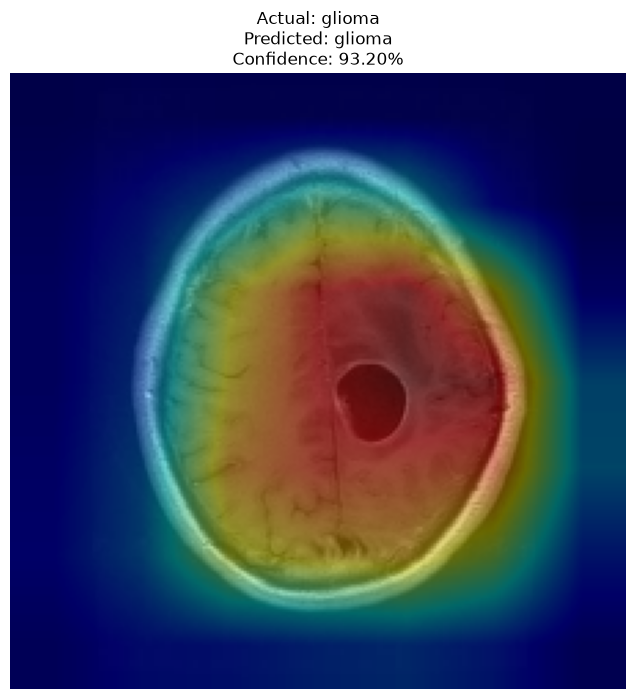

Actual: glioma | Predicted: glioma | Confidence: 93.20%
Grad-CAM saved to: ..\outputs\gradcam\glioma_Te-gl_2_gradcam.png
----------------------------------------------------------------------


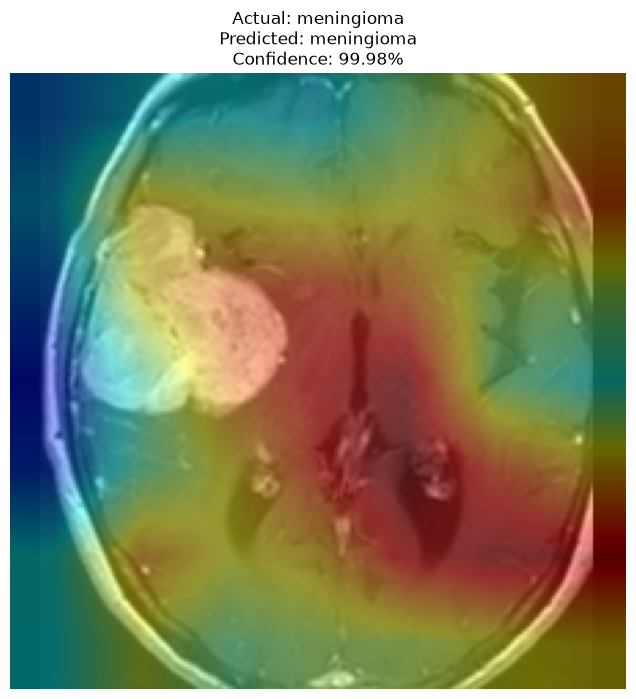

Actual: meningioma | Predicted: meningioma | Confidence: 99.98%
Grad-CAM saved to: ..\outputs\gradcam\meningioma_Te-me_2_gradcam.png
----------------------------------------------------------------------


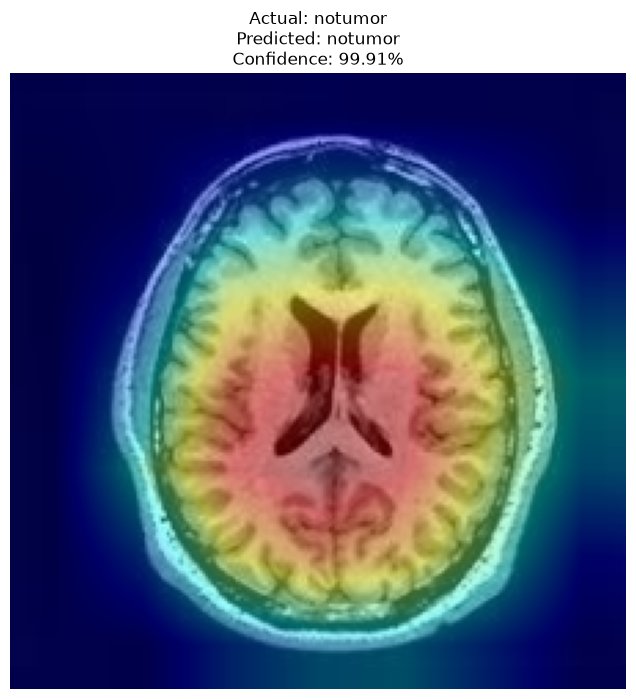

Actual: notumor | Predicted: notumor | Confidence: 99.91%
Grad-CAM saved to: ..\outputs\gradcam\notumor_Te-no_2_gradcam.png
----------------------------------------------------------------------


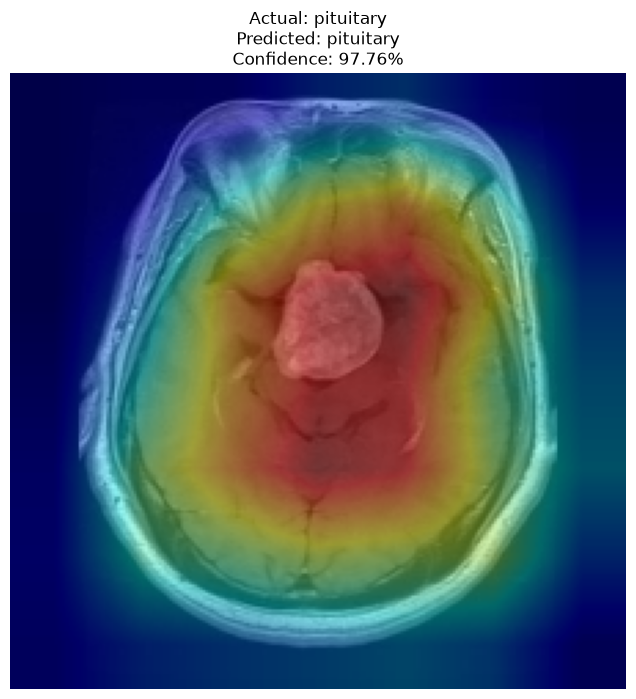

Actual: pituitary | Predicted: pituitary | Confidence: 97.76%
Grad-CAM saved to: ..\outputs\gradcam\pituitary_Te-pi_2_gradcam.png
----------------------------------------------------------------------


In [86]:
for actual_class, image_path in examples:

    (
        original_image,
        resized_image,
        image_batch,
        predictions,
        predicted_index,
        predicted_class,
        confidence
    ) = predict_image(image_path)

    heatmap = make_gradcam_heatmap(
        image_batch=image_batch,
        model=model,
        last_conv_layer_name=LAST_CONV_LAYER,
        pred_index=predicted_index
    )

    overlay = overlay_gradcam(
        resized_image,
        heatmap
    )

    image_name = Path(image_path).stem

    output_path = (
        OUTPUT_DIR /
        f"{actual_class}_{image_name}_gradcam.png"
    )

    plt.figure(figsize=(8, 8))

    plt.imshow(overlay)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    plt.axis("off")

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.1
    )

    plt.show()
    plt.close()

    print(
        f"Actual: {actual_class} | "
        f"Predicted: {predicted_class} | "
        f"Confidence: {confidence * 100:.2f}%"
    )

    print(f"Grad-CAM saved to: {output_path}")
    print("-" * 70)

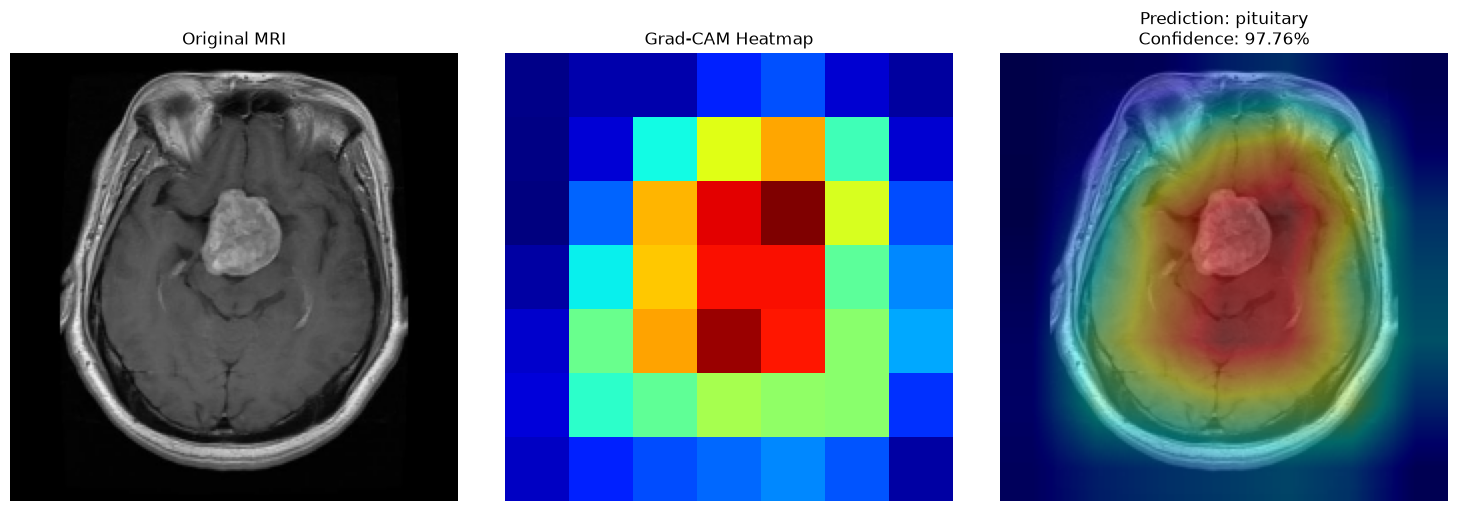

In [87]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(resized_image)
axes[0].set_title("Original MRI")
axes[0].axis("off")

axes[1].imshow(
    heatmap,
    cmap="jet"
)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)
axes[2].axis("off")

plt.tight_layout()

output_path = (
    OUTPUT_DIR /
    f"{actual_class}_{image_name}_gradcam.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()